# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Гнатюк Ярослав Богданович'
LIST_NUMBER  = 4

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 4, файл lr6_варіант_04.csv


> Файли варіантів лежать у теці `дані` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK = 'класифікація'

METRIC = 'AUC'

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.273

типи стовпців: {'object': 13, 'float64': 8, 'int64': 5}


In [6]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id_клієнта                      1200 non-null   object 
 1   вік                             1200 non-null   float64
 2   стать                           1200 non-null   object 
 3   місто                           1200 non-null   object 
 4   філія                           1200 non-null   object 
 5   тариф                           1200 non-null   object 
 6   тип_підключення                 1200 non-null   object 
 7   спосіб_оплати                   1200 non-null   object 
 8   автоплатіж                      1200 non-null   object 
 9   кількість_послуг                1200 non-null   int64  
 10  місяців_обслуговування          1200 non-null   float64
 11  швидкість_тарифу_Мбіт           1200 non-null   int64  
 12  щомісячний_платіж               11

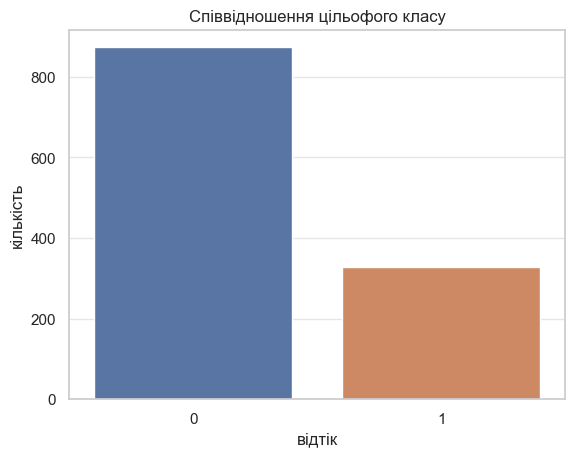

In [7]:
sns.set(style='whitegrid')

sns.countplot(data=raw, x='відтік', hue='відтік', legend=False)
plt.title('Співвідношення цільофого класу')
plt.ylabel('кількість')
plt.show()

In [8]:
overview = pd.DataFrame({
    'стовпець': raw.columns,
    'тип': [str(t) for t in raw.dtypes],
    'унікальних': raw.nunique().values,
    '% пропусків': (raw.isna().mean() * 100).round(1).values,
    'приклад': [raw[c].dropna().iloc[0] for c in raw.columns],
}).sort_values('% пропусків', ascending=False).reset_index(drop=True)
display(overview)

print()
print('рядків: %d, стовпців: %d' % raw.shape)
print('частка відтоку: %.3f; точність моделі «ніхто не піде»: %.3f' % (raw[TARGET].mean(), 1 - raw[TARGET].mean()))
print('текстових стовпців (object/str):', int((~raw.dtypes.map(pd.api.types.is_numeric_dtype)).sum()))
print('найбільше пропусків:', overview.iloc[0]['стовпець'], '-', overview.iloc[0]['% пропусків'], '%')

,стовпець,тип,унікальних,% пропусків,приклад
0,код_причини_закриття,object,5,72.8,ПЕР-01
1,сума_повернення_депозиту,float64,325,72.8,304.26
2,середній_час_відповіді_хв,float64,265,33.3,1.0
3,трафік_ГБ,object,962,5.0,50.9
4,щомісячний_платіж,object,1127,4.0,315.85
5,аварій_на_ділянці_за_квартал,float64,5,3.0,0.0
6,стать,object,6,0.0,ж
7,місто,object,6,0.0,Львів
8,id_клієнта,object,1200,0.0,K40000
9,вік,float64,62,0.0,41.0



рядків: 1200, стовпців: 26
частка відтоку: 0.273; точність моделі «ніхто не піде»: 0.728
текстових стовпців (object/str): 13
найбільше пропусків: код_причини_закриття - 72.8 %


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [9]:
for c in raw.columns:
    if not pd.api.types.is_numeric_dtype(raw[c]):
        s = raw[c].dropna()
        ok = pd.to_numeric(s, errors='coerce').notna()
        if 0 < ok.mean() < 1:
            print('%-20s розбирається як число: %.1f%%, нечислових: %d' % (c, 100 * ok.mean(), (~ok).sum()))

print()
txt = raw['щомісячний_платіж'].dropna()
print('текст у числовій колонці:')
print(txt[pd.to_numeric(txt, errors='coerce').isna()].head(6).tolist())

print()
tr = raw['трафік_ГБ'].dropna()
print('Excel перетворив число на дату:')
print(tr[pd.to_numeric(tr, errors='coerce').isna()].tolist())

print()
miss = raw['середній_час_відповіді_хв'].isna().rename('час відповіді не заповнений')
display(pd.crosstab(raw['кількість_звернень_у_підтримку'], miss))
print('частка відтоку: пропуск %.3f, заповнено %.3f' % (raw.loc[miss, TARGET].mean(), raw.loc[~miss, TARGET].mean()))

щомісячний_платіж    розбирається як число: 97.7%, нечислових: 27
трафік_ГБ            розбирається як число: 99.7%, нечислових: 3

текст у числовій колонці:
['205.49 грн', '199.39 грн', '208.14 грн', '263.93 грн', '235.74 грн', '324.0 грн']

Excel перетворив число на дату:
['1900-01-06 00:00:00', '1900-01-11 00:00:00', '1900-01-27 00:00:00']



час відповіді не заповнений,False,True
кількість_звернень_у_підтримку,,
0,0,400
1,437,0
2,227,0
3,108,0
4,22,0
5,6,0


частка відтоку: пропуск 0.193, заповнено 0.312


In [10]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'
PROBLEM_MNAR           = 'середній_час_відповіді_хв'
MNAR_MEANING           = 'Пропуск означає, що клієнт жодного разу не звертався в підтримку (звернень 0), тож час відповіді просто не було чого вимірювати'

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [11]:
DATE_RE = re.compile(r'^\s*\d{4}-\d{2}-\d{2}')
NUM_RE = re.compile(r'-?\d+(?:[.,]\d+)?')
NUM_LIKE = re.compile(r'\s*-?\d+(?:[.,]\d+)?\s*[^\W\d_]*\.?\s*')


def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        if v is None:
            return np.nan
        if isinstance(v, (datetime.datetime, datetime.date)):
            return np.nan
        if isinstance(v, (int, float, np.number)) and not isinstance(v, bool):
            return float(v)
        if pd.isna(v):
            return np.nan
        t = str(v)
        if DATE_RE.match(t):
            return np.nan
        m = NUM_RE.search(t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
assert np.isnan(to_number(pd.Series(['1900-01-06 00:00:00']))[0])
print('to_number працює')

to_number працює


In [12]:
DROP_ALWAYS = ['id_клієнта']

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        if c == 'дата_підключення':
            dt = pd.to_datetime(d[c], errors='coerce')
            X[c] = (dt - pd.Timestamp('2023-01-01')).dt.days.astype(float)
            how = 'дата -> число: днів від 2023-01-01'
        elif pd.api.types.is_numeric_dtype(d[c]):
            X[c] = d[c].astype(float)
            how = 'число'
        else:
            t = d[c].dropna().astype(str)
            share = t.map(lambda v: bool(NUM_LIKE.fullmatch(v) or DATE_RE.match(v))).mean()
            if share > 0.8:
                X[c] = to_number(d[c]).astype(float)
                how = 'число, витягнуте з тексту (%.0f%% значень)' % (100 * share)
            else:
                s = d[c].astype('object').map(lambda v: v.strip().lower() if isinstance(v, str) else v)
                if c == 'стать':
                    s = s.map(lambda v: v[0] if isinstance(v, str) else v)
                X[c] = s.astype('category')
                how = 'категорія, рівнів: %d' % X[c].nunique()
        log.append({'стовпець': c, 'рішення': how, 'пропусків': int(X[c].isna().sum())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,пропусків
0,вік,число,0
1,стать,"категорія, рівнів: 2",0
2,місто,"категорія, рівнів: 6",0
3,філія,"категорія, рівнів: 6",0
4,тариф,"категорія, рівнів: 4",0
5,тип_підключення,"категорія, рівнів: 3",0
6,спосіб_оплати,"категорія, рівнів: 3",0
7,автоплатіж,"категорія, рівнів: 2",0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


* `id_клієнта` викинуто: ідентифікатор лише запам'ятовується.
* `дата_підключення` стала числом: кількість днів від 2023-01-01.
* Текстовий стовпець вважається числовим, лише якщо **весь запис** схожий на «число + одиниця» (`NUM_LIKE`) у понад 80 % рядків; так `щомісячний_платіж` і `трафік_ГБ` стали числами. Звичайна умова «у тексті є число» помилилась би на `Ф-01 Центр` або `НОМ-035` (там «-01» і «-035» теж виглядають як числа), тому я перевіряю повний збіг.
* `стать` мала 6 написань (`ж`, `Ж`, `жін`, `ч`, `Ч`, `чол`): після приведення регістру й пробілів лишається 4, тому додатково береться перша літера, і виходить 2 рівні.
* `номер_договору_серія` лишається категорією з 55 рівнями: далі вона знадобиться як приклад хибної важливості.
* Підсумок: 24 ознаки, з них 9 категоріальних.

### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [13]:
def make_pipe(X, clf):
    num_cols = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat_cols = [c for c in X.columns if str(X[c].dtype) == 'category']
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.993


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [14]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.993 ± 0.003
час      : 1.1 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [15]:
FIRST_REACTION = ('AUC %.3f означає майже ідеальне розділення клієнтів, '
                  'а для передбачення поведінки людей це нереально, тож із двох причин (справжній сильний сигнал '
                  'чи витік цілі) найімовірніше спрацював витік: у даних є стовпці, яких у момент прогнозу не існує.'
                  % auc_naive.mean())
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.993 означає майже ідеальне розділення клієнтів, а для передбачення поведінки людей це нереально, тож із двох причин (справжній сильний сигнал чи витік цілі) найімовірніше спрацював витік: у даних є стовпці, яких у момент прогнозу не існує.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [16]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n1 = int(filled.sum())
        n0 = int((~filled).sum())
        if n1 >= min_group and n0 >= min_group:
            auc = roc_auc_score(y, filled.astype(int))
            score = max(auc, 1 - auc)
        else:
            score = 0.5
        rows.append({'ознака': c,
                     'заповнено': n1,
                     'частка_відтоку_де_заповнено': y[filled].mean() if n1 else np.nan,
                     'частка_відтоку_де_пропуск': y[~filled].mean() if n0 else np.nan,
                     'показник': score})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,сума_повернення_депозиту,327,1.000000,0.000000,1.000000
23,код_причини_закриття,327,1.000000,0.000000,1.000000
17,середній_час_відповіді_хв,800,0.312500,0.192500,0.567257
14,трафік_ГБ,1140,0.273684,0.250000,0.502837
12,щомісячний_платіж,1152,0.271701,0.291667,0.501934
16,аварій_на_ділянці_за_квартал,1164,0.273196,0.250000,0.501702
2,стать,1200,0.272500,NaN,0.500000
1,вік,1200,0.272500,NaN,0.500000
0,id_клієнта,1200,0.272500,NaN,0.500000
8,автоплатіж,1200,0.272500,NaN,0.500000


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [17]:
TARGET_LEAK = [
    'код_причини_закриття',
    'сума_повернення_депозиту',
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['код_причини_закриття', 'сума_повернення_депозиту']


* `код_причини_закриття`: причину закриття договору вносять тоді, коли договір уже закрито, тобто коли клієнт пішов; у чинного клієнта поля немає.
* `сума_повернення_депозиту`: депозит повертають за фактом розірвання договору, тож сума з'являється лише після відтоку.

In [18]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.972 ± 0.008


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [19]:
print(list(X2.columns))

single = {c: roc_auc_score(y, X2[c].fillna(X2[c].median()))
          for c in X2.columns if str(X2[c].dtype) != 'category'}
single = pd.Series(single).sub(0.5).abs().add(0.5).sort_values(ascending=False)
display(single.head(8).to_frame('AUC однієї ознаки'))

display(raw.groupby('оцінка_ризику_менеджером')[TARGET].agg(['mean', 'size']).round(3))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'номер_договору_серія', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


,AUC однієї ознаки
оцінка_ризику_менеджером,0.946953
річний_платіж,0.692310
щомісячний_платіж,0.686576
швидкість_тарифу_Мбіт,0.670464
місяців_обслуговування,0.655198
вік,0.620609
трафік_ГБ,0.610460
кількість_звернень_у_підтримку,0.591617


,mean,size
оцінка_ризику_менеджером,,
1.0,0.000,237
2.0,0.027,405
3.0,0.222,279
4.0,0.867,188
5.0,1.000,91


In [20]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',
]
HUMAN_LEAK_WHY = ('Поле заповнене в усіх рядках без жодного пропуску, тож детектор заповненості не бачить нічого: '
                  'витік сидить у самих значеннях, а не в наявності запису, бо менеджер виставляє оцінку, уже знаючи, чим усе закінчилось')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.846 ± 0.029


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

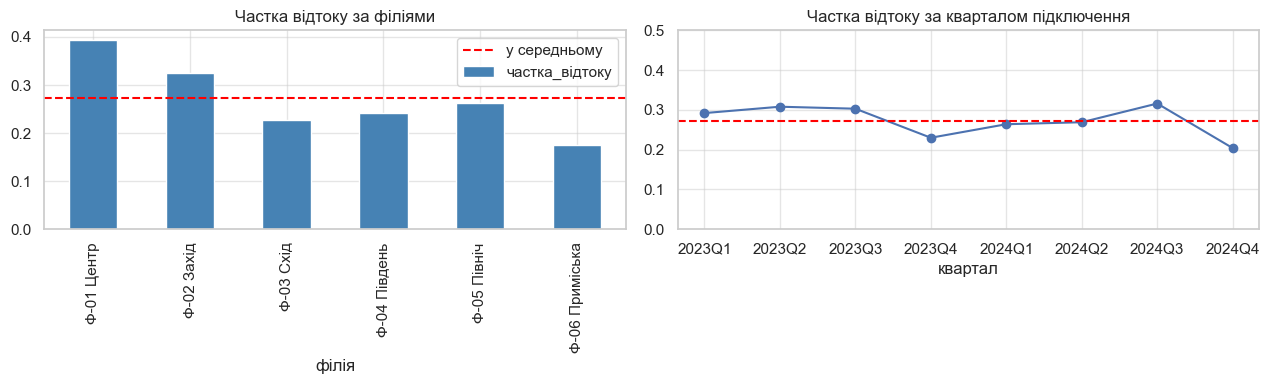

In [21]:
by_branch = (raw.groupby('філія')[TARGET].agg(['mean', 'size'])
             .rename(columns={'mean': 'частка_відтоку', 'size': 'клієнтів'}).round(3))

quarter = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q').astype(str).rename('квартал')
by_q = (raw.groupby(quarter)[TARGET].agg(['mean', 'size'])
        .rename(columns={'mean': 'частка_відтоку', 'size': 'клієнтів'}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_branch['частка_відтоку'].plot.bar(ax=axes[0], color='steelblue')
axes[0].axhline(raw[TARGET].mean(), color='red', ls='--', label='у середньому')
axes[0].set_title('Частка відтоку за філіями')
axes[0].legend()
by_q['частка_відтоку'].plot(marker='o', ax=axes[1])
axes[1].axhline(raw[TARGET].mean(), color='red', ls='--')
axes[1].set_title('Частка відтоку за кварталом підключення')
axes[1].set_ylim(0, 0.5)
plt.tight_layout()
plt.show()

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [22]:
SUSPECT = 'філія'
assert SUSPECT in ('філія', 'дата_підключення')

source = raw['філія'].isin(['Ф-01 Центр', 'Ф-02 Захід']).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.692
ті самі ознаки передбачають ВІДТІК  : AUC 0.834 ± 0.031


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [23]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.993
2. мінус цільовий витік,22,0.972
3. мінус оцінки людини,21,0.846
4. мінус артефакт збору,20,0.834


чесне число: 0.834 ± 0.031


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [24]:
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = ('Філія додає до AUC лише %.3f, а клієнти Ф-01 і Ф-02 помітно відрізняються складом (джерело вгадується з AUC %.2f), '
                'тому різниця у відтоку може бути наслідком способу збору, а не причиною; без філії модель можна переносити на нову філію, '
                'а Ф-01 і Ф-02 слід звітувати й моніторити окремо.' % (auc3.mean() - auc4.mean(), auc_src.mean()))
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — Філія додає до AUC лише 0.012, а клієнти Ф-01 і Ф-02 помітно відрізняються складом (джерело вгадується з AUC 0.69), тому різниця у відтоку може бути наслідком способу збору, а не причиною; без філії модель можна переносити на нову філію, а Ф-01 і Ф-02 слід звітувати й моніторити окремо.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [25]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.834,0.031,1.4
одне дерево,0.749,0.034,0.8
випадковий ліс,0.828,0.027,14.6
гістограмний бустинг,0.828,0.028,19.5


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [26]:
from scipy import stats


def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    half = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) * np.sqrt(1 / n + 1 / 4)
    return float(d.mean()), float(half)


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: -0.0060 ± 0.0266   у межах шуму
гістограмний бустинг   проти логістичної: -0.0064 ± 0.0225   у межах шуму


In [27]:
m_branch, h_branch = paired(auc4, auc3)
print('виграш від філії (X3 проти X4): %+0.4f ± %.4f   %s'
      % (m_branch, h_branch, 'значуще' if abs(m_branch) > h_branch else 'у межах шуму'))

model_scores = {name: cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
                for name, clf in MODELS.items()}
model_gain = {name: paired(base, sc) for name, sc in model_scores.items() if name != 'логістична регресія'}
display(pd.DataFrame(model_gain, index=['різниця AUC', '± 95%']).T.round(4))

виграш від філії (X3 проти X4): +0.0122 ± 0.0095   значуще


,різниця AUC,± 95%
одне дерево,-0.0852,0.0459
випадковий ліс,-0.0060,0.0266
гістограмний бустинг,-0.0064,0.0225


In [28]:
CHOSEN_MODEL = 'логістична регресія'
CHOSEN_WHY = ('За точністю ліс і бустинг не кращі (різниця з логістичною в межах шуму, AUC %.3f проти %.3f і %.3f), '
              'а логістична найшвидша (%.1f с проти %.1f і %.1f), найпростіша для пояснення відділу утримання '
              'а розкид майже такий самий.' % (
                  cmp_models.loc['логістична регресія', 'AUC'],
                  cmp_models.loc['випадковий ліс', 'AUC'],
                  cmp_models.loc['гістограмний бустинг', 'AUC'],
                  cmp_models.loc['логістична регресія', 'с на 100 навчань'],
                  cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                  cmp_models.loc['гістограмний бустинг', 'с на 100 навчань']))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: логістична регресія — За точністю ліс і бустинг не кращі (різниця з логістичною в межах шуму, AUC 0.834 проти 0.828 і 0.828), а логістична найшвидша (1.4 с проти 14.6 і 19.5), найпростіша для пояснення відділу утримання а розкид майже такий самий.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [29]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
    F['ціна_за_мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    F['трафік_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']
    F['платіж_на_послугу'] = F['щомісячний_платіж'] / F['кількість_послуг']
    return F.replace([np.inf, -np.inf], np.nan)


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [30]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.832 ± 0.031
приріст проти базового набору: -0.0024 ± 0.0026   у межах шуму


In [31]:
gain_feat = paired(base, auc5)
t0 = time.time()
cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
t_feat = time.time() - t0
t_lr_base = cmp_models.loc['логістична регресія', 'с на 100 навчань']
print('нові ознаки: %+0.4f ± %.4f за %.1f с (базова логістична %.1f с)' % (gain_feat + (t_feat, t_lr_base)))
for name, (g, hh) in model_gain.items():
    print('%-22s: %+0.4f ± %.4f за %.1f с' % (name, g, hh, cmp_models.loc[name, 'с на 100 навчань']))

нові ознаки: -0.0024 ± 0.0026 за 1.2 с (базова логістична 1.4 с)
одне дерево           : -0.0852 ± 0.0459 за 0.8 с
випадковий ліс        : -0.0060 ± 0.0266 за 14.6 с
гістограмний бустинг  : -0.0064 ± 0.0225 за 19.5 с


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [32]:
FEATURES_VS_MODEL = ('Жоден шлях не дав значущого приросту: нові ознаки %+.4f ± %.4f AUC за %.1f с, ліс %+.4f ± %.4f за %.1f с, '
                     'бустинг %+.4f ± %.4f за %.1f с; інтервали накривають нуль, тож найдешевший варіант (ознаки на простій логістичній) '
                     'не гірший, а складніша модель лише дорожча.' % (
                         gain_feat[0], gain_feat[1], t_feat,
                         model_gain['випадковий ліс'][0], model_gain['випадковий ліс'][1],
                         cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                         model_gain['гістограмний бустинг'][0], model_gain['гістограмний бустинг'][1],
                         cmp_models.loc['гістограмний бустинг', 'с на 100 навчань']))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Жоден шлях не дав значущого приросту: нові ознаки -0.0024 ± 0.0026 AUC за 1.2 с, ліс -0.0060 ± 0.0266 за 14.6 с, бустинг -0.0064 ± 0.0225 за 19.5 с; інтервали накривають нуль, тож найдешевший варіант (ознаки на простій логістичній) не гірший, а складніша модель лише дорожча.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [33]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.790
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

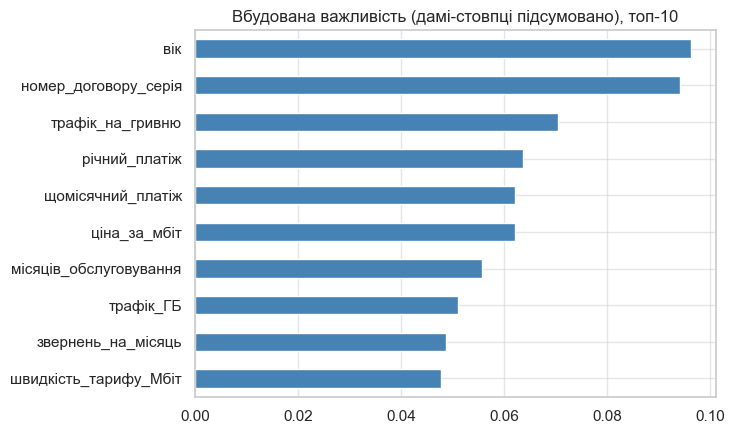

In [34]:
names_t = model.named_steps['prep'].get_feature_names_out()
cat_cols_final = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) == 'category']


def to_orig(n):
    n = n.split('__', 1)[1]
    if n in FINAL_X.columns:
        return n
    return max([c for c in cat_cols_final if n.startswith(c + '_')], key=len)


gini_raw = pd.Series(model.named_steps['clf'].feature_importances_, index=[to_orig(n) for n in names_t])
gini_imp = gini_raw.groupby(level=0).sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
gini_imp.head(10).iloc[::-1].plot.barh(ax=ax, color='steelblue')
ax.set_title('Вбудована важливість (дамі-стовпці підсумовано), топ-10')
plt.tight_layout()
plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [35]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.071818
місяців_обслуговування,0.037521
звернень_на_місяць,0.018194
річний_платіж,0.007908
швидкість_тарифу_Мбіт,0.006013
трафік_ГБ,0.005246
тип_підключення,0.005155
аварій_на_ділянці_за_квартал,0.004929
автоплатіж,0.002865
трафік_на_гривню,0.002255


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [36]:
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp}).sort_values('вбудована', ascending=False)
display(cmp_imp.head(10).round(4))

top5 = cmp_imp.head(5)
print('у топ-5 за вбудованою, а перестановочна близька до нуля або від\'ємна:')
display(top5[top5['перестановочна'] < 0.005].round(4))

,вбудована,перестановочна
вік,0.0964,0.0718
номер_договору_серія,0.0943,-0.0043
трафік_на_гривню,0.0705,0.0023
річний_платіж,0.0638,0.0079
щомісячний_платіж,0.0621,0.0020
ціна_за_мбіт,0.0621,-0.0076
місяців_обслуговування,0.0557,0.0375
трафік_ГБ,0.0511,0.0052
звернень_на_місяць,0.0488,0.0182
швидкість_тарифу_Мбіт,0.0478,0.0060


у топ-5 за вбудованою, а перестановочна близька до нуля або від'ємна:


,вбудована,перестановочна
номер_договору_серія,0.0943,-0.0043
трафік_на_гривню,0.0705,0.0023
щомісячний_платіж,0.0621,0.0020


In [37]:
FAKE_IMPORTANT = 'номер_договору_серія'
FAKE_IMPORTANT_WHY = ('Серія договору має 55 різних значень і не пов\'язана з відтоком, але після одиничного кодування дерево має 55 стовпців '
                      'і серед них майже завжди знаходить випадковий поріг, що трохи зменшує неоднорідність на навчальних даних, '
                      'тому сума вбудованих важливостей велика, а на перевірковій частині перемішування нічого не ламає.')
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: номер_договору_серія


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [38]:
num_cols = FINAL_X.select_dtypes('number').columns
corr = FINAL_X[num_cols].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
display(pairs.head(5).round(4).to_frame('|r|'))
display(pairs[pairs > 0.97].round(4).to_frame('|r| > 0.97'))

|r|
щомісячний_платіж     річний_платіж      0.9993
трафік_ГБ             трафік_на_гривню   0.8700
швидкість_тарифу_Мбіт щомісячний_платіж  0.7586
                      річний_платіж      0.7556
кількість_послуг      платіж_на_послугу  0.6846

,,|r| > 0.97
щомісячний_платіж,річний_платіж,0.9993


In [39]:
from sklearn.base import clone

DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

Xtr_d = Xtr.drop(columns=[DUP_PAIR[1]])
Xte_d = Xte.drop(columns=[DUP_PAIR[1]])
model_d = make_pipe(Xtr_d, clone(FINAL_CLF)).fit(Xtr_d, ytr)
perm_d = permutation_importance(model_d, Xte_d, yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_d = pd.Series(perm_d.importances_mean, index=Xte_d.columns)
auc_d = roc_auc_score(yte, model_d.predict_proba(Xte_d)[:, 1])

print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_d[DUP_PAIR[0]]))
print('AUC на відкладеній частині: з парою %.3f, без пари %.3f' % (auc_hold, auc_d))

у повній моделі:
   щомісячний_платіж            +0.0020
   річний_платіж                +0.0079
без річний_платіж:
   щомісячний_платіж            +0.0185
AUC на відкладеній частині: з парою 0.790, без пари 0.797


In [40]:
DUP_EXPLANATION = ('Платіж на місяць і платіж на рік відрізняються лише множником 12 (|r| = %.4f), тому модель бере інформацію з тієї колонки, '
                   'яку не зіпсували: у повній моделі важливість %+.4f і %+.4f, а коли друга колонка прибрана, '
                   'важливість першої зростає до %+.4f, бо вона лишилась єдиним носієм цього сигналу.'
                   % (corr.loc[DUP_PAIR[0], DUP_PAIR[1]], perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]], perm_d[DUP_PAIR[0]]))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

Платіж на місяць і платіж на рік відрізняються лише множником 12 (|r| = 0.9993), тому модель бере інформацію з тієї колонки, яку не зіпсували: у повній моделі важливість +0.0020 і +0.0079, а коли друга колонка прибрана, важливість першої зростає до +0.0185, бо вона лишилась єдиним носієм цього сигналу.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові ознаки без пропусків: ['вік', 'місяців_обслуговування', 'звернень_на_місяць']


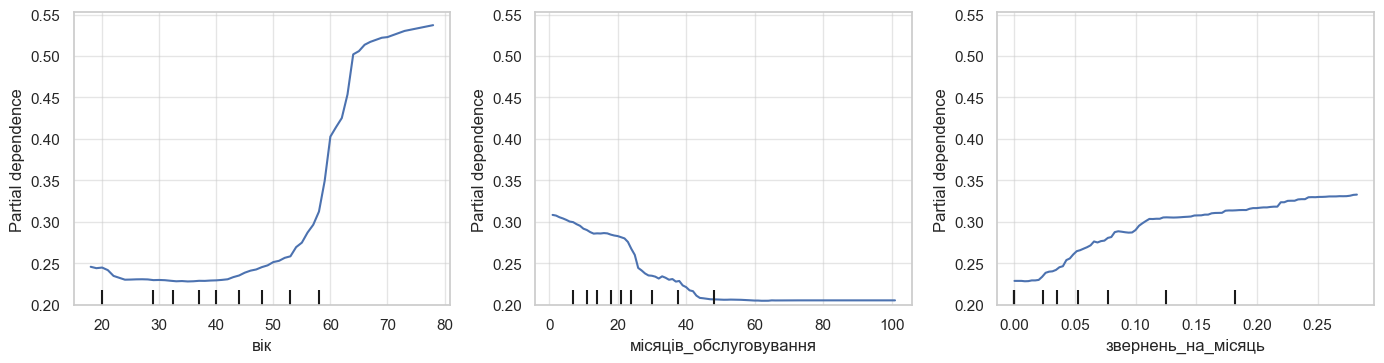

In [41]:
from sklearn.inspection import PartialDependenceDisplay

num_ranked = [c for c in perm_imp.index if str(FINAL_X[c].dtype) != 'category']
top_num = [c for c in num_ranked if FINAL_X[c].notna().all()][:3]
print('три найважливіші числові ознаки без пропусків:', top_num)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
PartialDependenceDisplay.from_estimator(model, Xte, features=top_num, kind='average', ax=ax)
plt.tight_layout()
plt.show()


* `вік`: майже плоска крива близько 0,23 від 25 до 43 років, трохи вища (0,25) у найменших (18 років), далі зростає: 0,29 у 56 років і 0,43 у 62. Тобто ризик різко підвищується для клієнтів старшого віку.
* `місяців_обслуговування`: монотонне спадання з 0,30 для 5 місяців до 0,21 після приблизно 43 місяців: що довше клієнт з нами, то менший ризик.
* `звернень_на_місяць`: монотонне зростання з 0,23 до 0,33: що частіше нормовані на стаж звернення, то вищий ризик (із застереженням з розділу 12.2).

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

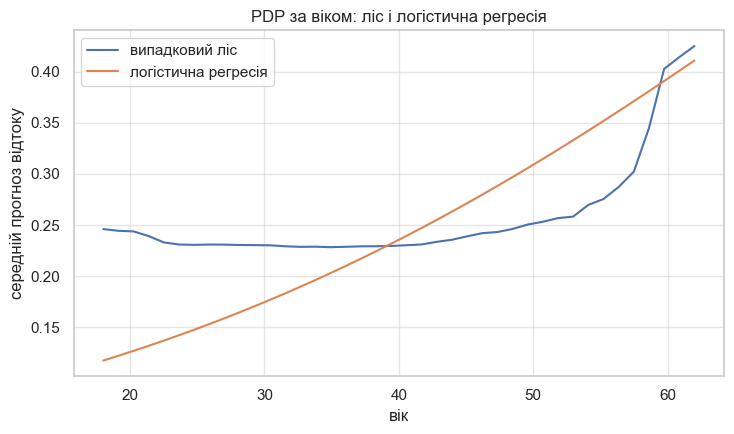

In [42]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label, mdl in [('випадковий ліс', model), ('логістична регресія', lr_model)]:
    r = partial_dependence(mdl, Xte, [NONLINEAR_FEATURE], kind='average', grid_resolution=40)
    ax.plot(r['grid_values'][0], r['average'][0], label=label)
ax.set_xlabel(NONLINEAR_FEATURE)
ax.set_ylabel('середній прогноз відтоку')
ax.set_title('PDP за віком: ліс і логістична регресія')
ax.legend()
plt.tight_layout()
plt.show()

In [43]:
NONLINEAR_MEANING = ('Ризик відтоку найнижчий і майже однаковий у віці приблизно 25-45 років (мінімум близько 35), трохи вищий у наймолодших '
                     'і різко зростає після 55 років: літні клієнти розривають договір значно частіше, а наймолодші трохи легше змінюють провайдера.')
NONLINEAR_FIX = 'Квадрат відхилення віку від точки мінімуму ризику, (вік - AGE_MIN)^2, де AGE_MIN зчитано з PDP лісу.'
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

Ризик відтоку найнижчий і майже однаковий у віці приблизно 25-45 років (мінімум близько 35), трохи вищий у наймолодших і різко зростає після 55 років: літні клієнти розривають договір значно частіше, а наймолодші трохи легше змінюють провайдера.
Квадрат відхилення віку від точки мінімуму ризику, (вік - AGE_MIN)^2, де AGE_MIN зчитано з PDP лісу.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [44]:
r_age = partial_dependence(model, Xte, ['вік'], kind='average', grid_resolution=40)
AGE_MIN = float(r_age['grid_values'][0][np.argmin(r_age['average'][0])])
print('мінімум ризику за лісом при віці %.1f' % AGE_MIN)

FX_q = FINAL_X.assign(вік_відхилення_кв=(FINAL_X['вік'] - AGE_MIN) ** 2)
base_lr = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
quad_lr = cross_val_score(make_pipe(FX_q, logreg()), FX_q, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(base_lr, quad_lr)
print('логістична без ознаки: AUC %.3f; з ознакою: AUC %.3f' % (base_lr.mean(), quad_lr.mean()))
print('приріст %+0.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

мінімум ризику за лісом при віці 34.9
логістична без ознаки: AUC 0.832; з ознакою: AUC 0.854
приріст +0.0221 ± 0.0134   значуще


In [45]:
QUAD_GAIN = float(m_q)
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0221


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

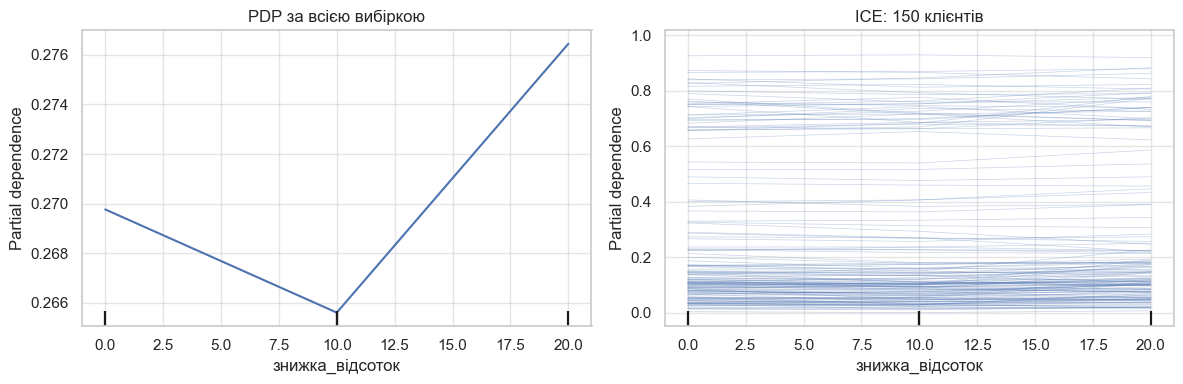

клієнтів, для яких знижка 20% підвищує прогноз: 54%, знижує: 40%
середній PDP: 0.270 0.266 0.276


In [46]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='average', ax=ax[0])
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind='individual',
                                        subsample=150, random_state=SEED, ax=ax[1])
ax[0].set_title('PDP за всією вибіркою')
ax[1].set_title('ICE: 150 клієнтів')
plt.tight_layout()
plt.show()

ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
slope = ice[:, -1] - ice[:, 0]
print('клієнтів, для яких знижка 20%% підвищує прогноз: %.0f%%, знижує: %.0f%%' % (100 * (slope > 0).mean(), 100 * (slope < 0).mean()))
print('середній PDP: %s' % ' '.join('%.3f' % v for v in partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')['average'][0]))

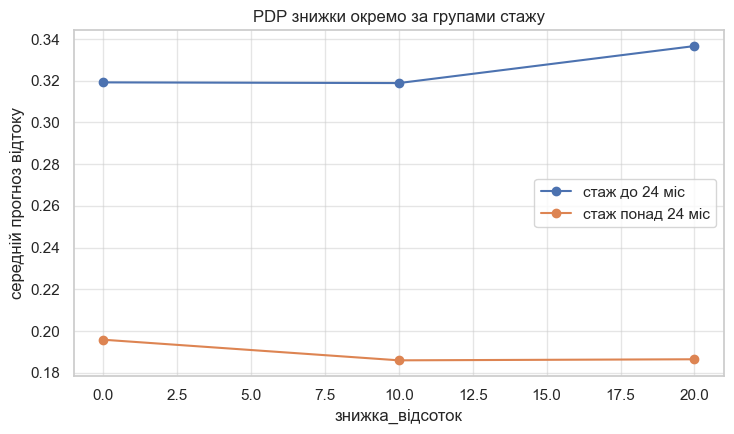

,стаж до 24 міс,стаж понад 24 міс
0,0.319,0.196
10,0.319,0.186
20,0.337,0.186


In [47]:
mask_new = FINAL_X['місяців_обслуговування'] <= 24

fig, ax = plt.subplots(figsize=(7.5, 4.5))
pdp_groups = {}
for label, mk in [('стаж до 24 міс', mask_new), ('стаж понад 24 міс', ~mask_new)]:
    r = partial_dependence(model, FINAL_X[mk], ['знижка_відсоток'], kind='average')
    pdp_groups[label] = r['average'][0]
    ax.plot(r['grid_values'][0], r['average'][0], marker='o', label=label)
ax.set_xlabel('знижка_відсоток')
ax.set_ylabel('середній прогноз відтоку')
ax.set_title('PDP знижки окремо за групами стажу')
ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(pdp_groups, index=[0, 10, 20]).round(3))

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [48]:
grp = np.where(raw['місяців_обслуговування'] <= 24, 'до 24 міс', 'понад 24 міс')
churn_tbl = raw.pivot_table(index='знижка_відсоток', columns=grp, values=TARGET, aggfunc='mean')
size_tbl = raw.pivot_table(index='знижка_відсоток', columns=grp, values=TARGET, aggfunc='size')
display(pd.concat({'частка відтоку': churn_tbl.round(3), 'клієнтів': size_tbl}, axis=1))

частка відтоку               клієнтів             
                     до 24 міс понад 24 міс до 24 міс понад 24 міс
знижка_відсоток                                                   
0                        0.324        0.253       306          166
10                       0.332        0.128       217          187
20                       0.434        0.039       196          128

In [49]:
INTERACTION_FOUND = ('Знижка діє в різні боки: у клієнтів зі стажем до 24 міс частка відтоку зі знижкою 20%% навіть вища (%.0f%% проти %.0f%% без знижки), '
                     'а у клієнтів зі стажем понад 24 міс знижка різко знижує відтік (з %.0f%% без знижки до %.0f%% зі знижкою 20%%), '
                     'тож в середньому по вибірці ефект майже непомітний.'
                     % (100 * churn_tbl.loc[20, 'до 24 міс'], 100 * churn_tbl.loc[0, 'до 24 міс'],
                        100 * churn_tbl.loc[0, 'понад 24 міс'], 100 * churn_tbl.loc[20, 'понад 24 міс']))
BUSINESS_ACTION = ('Пропонувати знижку лише давнім клієнтам (стаж понад 24 міс), де вона найсильніше утримує, '
                   'і не роздавати її новим, де вона не допомагає; ефект варто перевірити контрольованим експериментом.')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

Знижка діє в різні боки: у клієнтів зі стажем до 24 міс частка відтоку зі знижкою 20% навіть вища (43% проти 32% без знижки), а у клієнтів зі стажем понад 24 міс знижка різко знижує відтік (з 25% без знижки до 4% зі знижкою 20%), тож в середньому по вибірці ефект майже непомітний.
Пропонувати знижку лише давнім клієнтам (стаж понад 24 міс), де вона найсильніше утримує, і не роздавати її новим, де вона не допомагає; ефект варто перевірити контрольованим експериментом.


In [50]:
FX_i = FINAL_X.assign(знижка_x_стаж=FINAL_X['знижка_відсоток'] * FINAL_X['місяців_обслуговування'])
inter_lr = cross_val_score(make_pipe(FX_i, logreg()), FX_i, y, cv=cv, scoring='roc_auc')
m_i, h_i = paired(base_lr, inter_lr)
print('логістична з добутком «знижка x стаж»: AUC %.3f' % inter_lr.mean())
print('приріст %+0.4f ± %.4f   %s' % (m_i, h_i, 'значуще' if abs(m_i) > h_i else 'у межах шуму'))

логістична з добутком «знижка x стаж»: AUC 0.840
приріст +0.0087 ± 0.0054   значуще


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [51]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 92)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

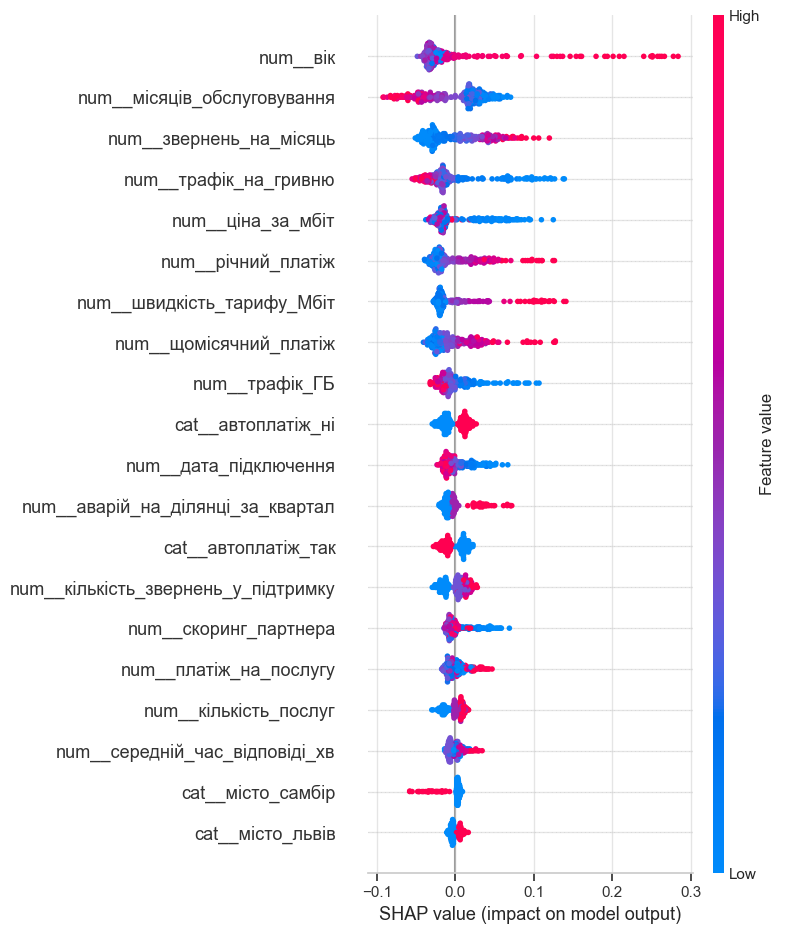

In [52]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [53]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
risk_top = model.predict_proba(Xte)[:SAMPLE, 1][idx]
print('ризик клієнта: %.3f' % risk_top)

contrib = pd.Series(sv1[idx], index=feat_names)
by_feature = contrib.groupby([to_orig(n) for n in feat_names]).sum()
top3 = by_feature.reindex(by_feature.abs().sort_values(ascending=False).index).head(3)
client = Xte.iloc[idx]
display(pd.DataFrame({'внесок': top3, 'значення у клієнта': [client[c] for c in top3.index]}).round(3))
print('базовий рівень %.3f + сума внесків %+.3f = %.3f (ризик клієнта %.3f)'
      % (np.ravel(expl.expected_value)[-1], contrib.sum(), np.ravel(expl.expected_value)[-1] + contrib.sum(), risk_top))

ризик клієнта: 0.850


,внесок,значення у клієнта
швидкість_тарифу_Мбіт,0.120,1000.00
річний_платіж,0.095,7160.40
щомісячний_платіж,0.093,600.26


базовий рівень 0.273 + сума внесків +0.577 = 0.850 (ризик клієнта 0.850)


In [54]:
NICE = {
    'вік': 'вік клієнта', 'стать': 'стать', 'місто': 'місто', 'тариф': 'тариф', 'тип_підключення': 'тип підключення',
    'спосіб_оплати': 'спосіб оплати', 'автоплатіж': 'автоплатіж', 'кількість_послуг': 'кількість підключених послуг',
    'місяців_обслуговування': 'скільки місяців клієнт з нами', 'швидкість_тарифу_Мбіт': 'швидкість тарифу',
    'щомісячний_платіж': 'щомісячний платіж', 'знижка_відсоток': 'розмір знижки', 'трафік_ГБ': 'обсяг трафіку',
    'кількість_звернень_у_підтримку': 'кількість звернень у підтримку', 'аварій_на_ділянці_за_квартал': 'аварії на ділянці',
    'середній_час_відповіді_хв': 'час відповіді підтримки', 'річний_платіж': 'сума платежів за рік',
    'номер_договору_серія': 'серія договору', 'скоринг_партнера': 'скоринг партнера', 'дата_підключення': 'дата підключення',
    'звернень_на_місяць': 'частота звернень у підтримку', 'ціна_за_мбіт': 'ціна за одиницю швидкості',
    'трафік_на_гривню': 'трафік на гривню платежу', 'платіж_на_послугу': 'платіж на одну послугу',
}


def say(orig, value):
    if isinstance(value, (float, np.floating)):
        value = ('%.1f' % value).rstrip('0').rstrip('.')
    return '%s (%s)' % (NICE.get(orig, orig), value)


parts = []
for orig, val in top3.items():
    direction = 'підвищує' if val > 0 else 'знижує'
    parts.append('%s %s ризик' % (say(orig, client[orig]), direction))
EXPLANATION_FOR_MANAGER = ('Цього клієнта ми вважаємо дуже ризикованим: ймовірність, що він піде, близько %.0f%%. '
                           'Найбільше на це впливає: %s; %s; %s. '
                           'Це пояснює, чому саме його варто набрати першим, але не гарантує, що зміна цих обставин його втримає.'
                           % ((100 * risk_top,) + tuple(parts)))
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Цього клієнта ми вважаємо дуже ризикованим: ймовірність, що він піде, близько 85%. Найбільше на це впливає: швидкість тарифу (1000) підвищує ризик; сума платежів за рік (7160.4) підвищує ризик; щомісячний платіж (600.3) підвищує ризик. Це пояснює, чому саме його варто набрати першим, але не гарантує, що зміна цих обставин його втримає.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [55]:
SHAP_NOT_CAUSAL_FEATURE = 'вік'
SHAP_NOT_CAUSAL_WHY = ('Вік має найбільший внесок (клієнти від 55 років йдуть значно частіше), але ні відділ утримання, ні знижка не можуть змінити '
                       'вік клієнта, тож втручатися нема в що; значення Шеплі лише показують, що модель користується віком як маркером ризику, '
                       'а не що вік спричиняє відтік.')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — Вік має найбільший внесок (клієнти від 55 років йдуть значно частіше), але ні відділ утримання, ні знижка не можуть змінити вік клієнта, тож втручатися нема в що; значення Шеплі лише показують, що модель користується віком як маркером ризику, а не що вік спричиняє відтік.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [56]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",номер_договору_серія,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [57]:
auc_one = {c: roc_auc_score(y, FINAL_X[c].fillna(FINAL_X[c].median()))
           for c in ['звернень_на_місяць', 'кількість_звернень_у_підтримку', 'місяців_обслуговування']}
print('AUC однієї ознаки:', {k: round(v, 3) for k, v in auc_one.items()})
print('кореляція звернень_на_місяць з 1/(стаж+1): %.3f' % np.corrcoef(FINAL_X['звернень_на_місяць'], 1 / (FINAL_X['місяців_обслуговування'] + 1))[0, 1])
print('перестановочна важливість: звернень_на_місяць %+.4f, кількість_звернень %+.4f, місяців_обслуговування %+.4f'
      % (perm_imp['звернень_на_місяць'], perm_imp['кількість_звернень_у_підтримку'], perm_imp['місяців_обслуговування']))

AUC однієї ознаки: {'звернень_на_місяць': 0.645, 'кількість_звернень_у_підтримку': 0.592, 'місяців_обслуговування': 0.345}
кореляція звернень_на_місяць з 1/(стаж+1): 0.483
перестановочна важливість: звернень_на_місяць +0.0182, кількість_звернень -0.0010, місяців_обслуговування +0.0375


In [58]:
FIFTH_MISTAKE = ('Сконструйована ознака «звернень_на_місяць» стоїть на третьому місці за перестановочною важливістю (%+.4f), '
                 'а сирий лічильник звернень майже нічого не важить (%+.4f): ознака ділить звернення на (стаж + 1), тож її важливість частково '
                 'відображає поєднання з коротким стажем, а не саму кількість дзвінків; крім того, дзвінок до підтримки може бути наслідком наміру піти, '
                 'тому читати її як «звернення спричиняють відтік» не можна.'
                 % (perm_imp['звернень_на_місяць'], perm_imp['кількість_звернень_у_підтримку']))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Сконструйована ознака «звернень_на_місяць» стоїть на третьому місці за перестановочною важливістю (+0.0182), а сирий лічильник звернень майже нічого не важить (-0.0010): ознака ділить звернення на (стаж + 1), тож її важливість частково відображає поєднання з коротким стажем, а не саму кількість дзвінків; крім того, дзвінок до підтримки може бути наслідком наміру піти, тому читати її як «звернення спричиняють відтік» не можна.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [59]:
TOP_N = 100
proba = model.predict_proba(Xte)[:, 1]
order = np.argsort(-proba)[:TOP_N]
top_rate = float(yte.iloc[order].mean())
base_rate = float(yte.mean())
lift = top_rate / base_rate
print('у перевірковій частині %d клієнтів, пішло %d (%.1f%%)' % (len(yte), yte.sum(), 100 * base_rate))
print('серед топ-%d за оцінкою ризику пішло %d (%.1f%%); навмання очікували б %.0f' % (TOP_N, yte.iloc[order].sum(), 100 * top_rate, TOP_N * base_rate))
print('lift = %.2f' % lift)
print('AUC на відкладеній частині: %.3f' % auc_hold)

у перевірковій частині 360 клієнтів, пішло 98 (27.2%)
серед топ-100 за оцінкою ризику пішло 57 (57.0%); навмання очікували б 27
lift = 2.09
AUC на відкладеній частині: 0.790


In [60]:
LIFT_MEANING = ('Список із 100 клієнтів містить відтоку в %.1f раза більше, ніж обдзвін навмання: %.0f%% проти %.0f%% у середньому.'
                % (lift, 100 * top_rate, 100 * base_rate))
assert LIFT_MEANING
print(LIFT_MEANING)

Список із 100 клієнтів містить відтоку в 2.1 раза більше, ніж обдзвін навмання: 57% проти 27% у середньому.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [61]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_04.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [62]:
major_acc = 1 - raw[TARGET].mean()
ci_top = 1.96 * np.sqrt(top_rate * (1 - top_rate) / TOP_N)
dropped = DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT]

REPORT = f'''
1. Метрика AUC, бо відтік трапляється у {raw[TARGET].mean():.1%} клієнтів: модель «ніхто не піде» дала б точність {major_acc:.1%} і не знайшла б жодного клієнта ризику, а AUC такої моделі лише 0,5 і не залежить від порога. Схема перевірки: стратифікована 5-кратна з 4 повторами (20 оцінок).
2. Викинуто: {', '.join(dropped)}. id_клієнта є лише ідентифікатором. код_причини_закриття і сума_повернення_депозиту з'являються після розірвання договору (заповнені тільки в тих, хто пішов), детектор 5.1 знайшов обидва з показником 1,0. оцінка_ризику_менеджером виставляється менеджером постфактум; детектор її не знайшов, бо поле заповнене в усіх рядках, а витік у значеннях. філія викинута як підозрюваний артефакт збору.
3. Чесне число: AUC {HONEST_AUC:.3f} ± {auc4.std():.3f} (стандартне відхилення за 20 згортками), а наївне було {auc_naive.mean():.3f}. Різниця двох моделей у 0,004 набагато менша за розкид і за півширину інтервалу (близько {model_gain["випадковий ліс"][1]:.3f}), тож це шум.
4. Артефакт збору: ті самі ознаки передбачають належність до Ф-01 або Ф-02 з AUC {auc_src.mean():.3f} (0,5 було б «нічого»), а частка відтоку в цих філіях {by_branch.loc["Ф-01 Центр", "частка_відтоку"]:.0%} і {by_branch.loc["Ф-02 Захід", "частка_відтоку"]:.0%} проти {by_branch.drop(["Ф-01 Центр", "Ф-02 Захід"])["частка_відтоку"].min():.0%}-{by_branch.drop(["Ф-01 Центр", "Ф-02 Захід"])["частка_відтоку"].max():.0%} в інших. Різкої сходинки немає, а за датою підключення її немає зовсім; моделі в новій філії довіряти слід обережно і спершу перевірити її на місцевих даних.
5. Нові ознаки: {gain_feat[0]:+.4f} ± {gain_feat[1]:.4f} AUC за {t_feat:.1f} с; складніша модель: ліс {model_gain["випадковий ліс"][0]:+.4f} ± {model_gain["випадковий ліс"][1]:.4f} за {cmp_models.loc["випадковий ліс", "с на 100 навчань"]:.1f} с, бустинг {model_gain["гістограмний бустинг"][0]:+.4f} ± {model_gain["гістограмний бустинг"][1]:.4f} за {cmp_models.loc["гістограмний бустинг", "с на 100 навчань"]:.1f} с. Жоден приріст не значущий.
6. Хибно важлива за вбудованою важливістю: {FAKE_IMPORTANT} (вбудована {gini_imp[FAKE_IMPORTANT]:.3f}, друге місце; перестановочна {perm_imp[FAKE_IMPORTANT]:+.4f}). Ознака з багатьма різними значеннями дає дереву безліч порогів, серед яких завжди знайдеться такий, що трохи зменшує неоднорідність навіть без зв'язку з ціллю.
7. Пара {DUP_PAIR[0]} і {DUP_PAIR[1]}: у повній моделі важливості {perm_imp[DUP_PAIR[0]]:+.4f} і {perm_imp[DUP_PAIR[1]]:+.4f}, а без другої колонки важливість першої {perm_d[DUP_PAIR[0]]:+.4f}. Це точна відповідь на питання «що буде без цієї ознаки», бо інформація лишається в дублі; помилка лише в читанні «важливість мала, отже ознаку можна викинути».
8. Немонотонний вплив має {NONLINEAR_FEATURE}: ризик мінімальний близько {AGE_MIN:.0f} років і зростає в обидва боки. Логістична регресія без втручання цього не бачить (лише пряма), а ознака (вік - {AGE_MIN:.0f})^2 дала їй {QUAD_GAIN:+.4f} AUC.
9. PDP за знижкою майже плаский ({" ".join("%.3f" % v for v in partial_dependence(model, FINAL_X, ["знижка_відсоток"], kind="average")["average"][0])}), хоча в сирих даних знижка 20% у клієнтів зі стажем понад 24 міс знижує відтік з {churn_tbl.loc[0, "понад 24 міс"]:.0%} до {churn_tbl.loc[20, "понад 24 міс"]:.0%}, а в клієнтів зі стажем до 24 міс підвищує його з {churn_tbl.loc[0, "до 24 міс"]:.0%} до {churn_tbl.loc[20, "до 24 міс"]:.0%}. ICE показав, що для {(slope > 0).mean():.0%} клієнтів знижка підвищує прогноз, а для {(slope < 0).mean():.0%} знижує.
10. {SHAP_NOT_CAUSAL_FEATURE}: великий внесок за Шеплі, але змінити вік неможливо. «Модель цим користується» означає кореляцію в даних, «це причина» вимагає причинного висновку, якого без експерименту немає.
11. Замовнику: у списку зі 100 найризикованіших клієнтів відтік {top_rate:.0%} проти {base_rate:.0%} у середньому, lift {lift:.2f}; AUC {auc_hold:.3f} на відкладеній частині. Застереження: оцінка зроблена на одному поділі з {len(yte)} клієнтів, тож частка в списку має похибку близько ±{ci_top:.0%}, а також ми не знаємо, чи знижка втримає саме цих людей, бо причинності модель не доводить.

Декларація про використання ШІ: Під час виконання роботи використано Claude: код усіх розділів, пояснення в окремих комірках і текстові відповіді підготовлено з його участю. Ноутбук виконано повністю згори вниз, числа у звіті звірено з виводом комірок, дані й висновки по інтерпретації перевірено за власними таблицями та графіками (PDP, ICE, SHAP).
'''
print(REPORT)


1. Метрика AUC, бо відтік трапляється у 27.3% клієнтів: модель «ніхто не піде» дала б точність 72.8% і не знайшла б жодного клієнта ризику, а AUC такої моделі лише 0,5 і не залежить від порога. Схема перевірки: стратифікована 5-кратна з 4 повторами (20 оцінок).
2. Викинуто: id_клієнта, код_причини_закриття, сума_повернення_депозиту, оцінка_ризику_менеджером, філія. id_клієнта є лише ідентифікатором. код_причини_закриття і сума_повернення_депозиту з'являються після розірвання договору (заповнені тільки в тих, хто пішов), детектор 5.1 знайшов обидва з показником 1,0. оцінка_ризику_менеджером виставляється менеджером постфактум; детектор її не знайшов, бо поле заповнене в усіх рядках, а витік у значеннях. філія викинута як підозрюваний артефакт збору.
3. Чесне число: AUC 0.834 ± 0.031 (стандартне відхилення за 20 згортками), а наївне було 0.993. Різниця двох моделей у 0,004 набагато менша за розкид і за півширину інтервалу (близько 0.027), тож це шум.
4. Артефакт збору: ті самі ознаки пе

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.